In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi



In [4]:
prefix = '/mnt/staging/'
fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

load_path = str(PREPARES / "heterogeneity") + "/"
# where M2 S1 indices are
load_contour_path = str(PREPARES / "heterogeneity-contours") + "/"



palatte_dict = load_pickle(figure_config_root+'palatte_dict')

In [15]:

bdp_w_order = ['LFP','RFP','LHP','RHP','LM','RM','LW','RW','LN','RN','LV','RV']
mice_list = ['cm125','cm193','cm229','cm216','cm126','cm128']



In [17]:
S1_time_course = {key:[] for key in bdp_w_order}
M2_time_course = {key:[] for key in bdp_w_order}
for mouse in mice_list:
    # load resting-state data in
    with h5py.File(load_path+mouse+'_all_concat_500_regions', 'r') as h5file:
        H_jrgeco = np.array(h5file['H_jrgeco'])
    # load M2 and S1 indices
    dict_save = load_pickle(load_contour_path+'dict_save_'+mouse)
    sensory_ind = dict_save['sensory_ind']
    M2_ind = dict_save['M2_ind']        
    for bdp in bdp_w_order:
        S1_time_course[bdp].append(H_jrgeco[sensory_ind[bdp],:])
        M2_time_course[bdp].append(H_jrgeco[M2_ind[bdp],:])
    
for bdp in bdp_w_order:
    S1_time_course[bdp] = np.concatenate(S1_time_course[bdp])
    M2_time_course[bdp] = np.concatenate(M2_time_course[bdp])
    


In [19]:
S1_time_course.keys()

dict_keys(['LFP', 'RFP', 'LHP', 'RHP', 'LM', 'RM', 'LW', 'RW', 'LN', 'RN', 'LV', 'RV'])

In [20]:
M2_time_course.keys()

dict_keys(['LFP', 'RFP', 'LHP', 'RHP', 'LM', 'RM', 'LW', 'RW', 'LN', 'RN', 'LV', 'RV'])

In [21]:
S1_time_course['LFP'].shape

(533908,)

In [22]:
M2_time_course['LFP'].shape

(533908,)

In [40]:
# Parameters
n_samples = 500
window_size = 5000
n_timepoints = 533908

# Random start indices for the blocks
rng = np.random.default_rng(seed=42)  # for reproducibility
start_indices = rng.integers(0, n_timepoints - window_size, size=n_samples)

# Where to store results
results = {}

body_parts = S1_time_course.keys()

for body in body_parts:
    s1 = S1_time_course[body]
    m2 = M2_time_course[body]

    orig_corrs = []
    shuf_corrs = []

    for start in start_indices:
        end = start + window_size
        s1_block = s1[start:end]
        m2_block = m2[start:end]

        # Normalize (demean and std) to avoid bias
        s1_z = (s1_block - np.mean(s1_block)) / np.std(s1_block)
        m2_z = (m2_block - np.mean(m2_block)) / np.std(m2_block)

        # Original correlation
        r_orig = np.mean(s1_z * m2_z)
        orig_corrs.append(np.arctanh(r_orig))

        # Circularly shift s1_block by a random offset
        shift = rng.integers(1, window_size)
        s1_shuf = np.roll(s1_z, shift)

        # Shuffled correlation
        r_shuf = np.mean(s1_shuf * m2_z)
        shuf_corrs.append(np.arctanh(r_shuf))

    # Store in dict
    results[body] = {
        'original': np.array(orig_corrs),
        'shuffled': np.array(shuf_corrs)
    }



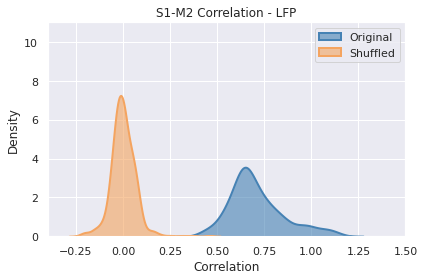

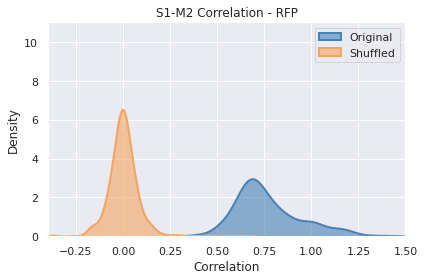

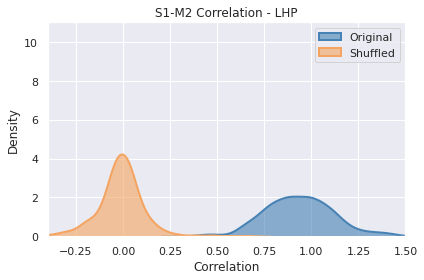

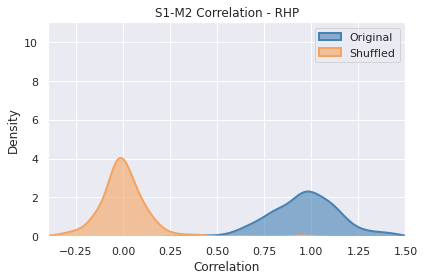

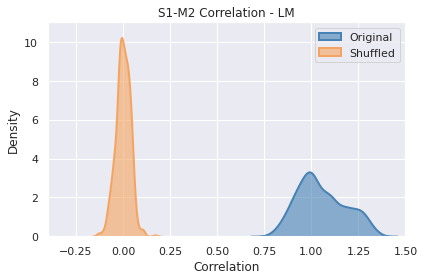

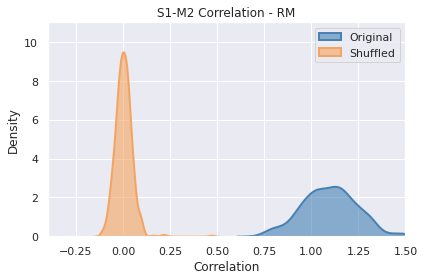

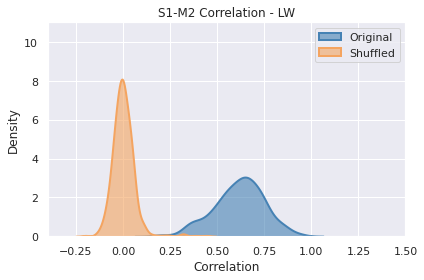

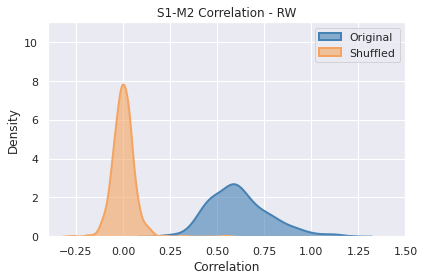

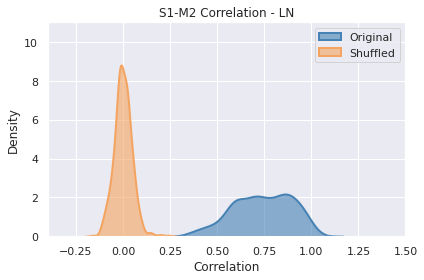

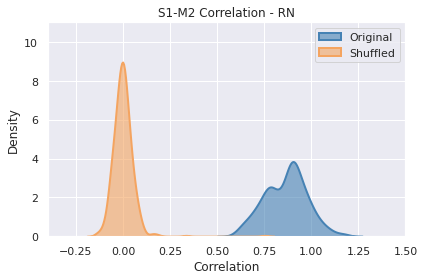

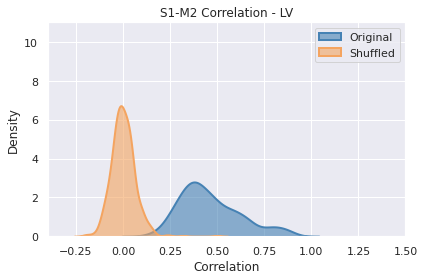

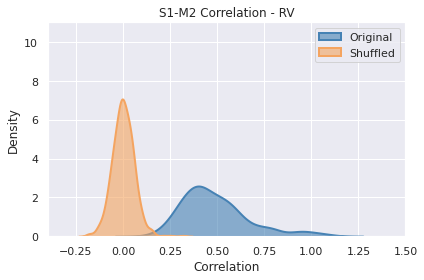

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

for body in body_parts:
    plt.figure(figsize=(6,4))
    
    sns.kdeplot(
        results[body]['original'],
        fill=True,
        label='Original',
        color='steelblue',
        alpha=0.6,
        linewidth=2
    )
    
    sns.kdeplot(
        results[body]['shuffled'],
        fill=True,
        label='Shuffled',
        color='sandybrown',
        alpha=0.6,
        linewidth=2
    )
    
    plt.title(f'S1-M2 Correlation - {body}')
    plt.xlabel('Correlation')
    plt.xlim([-0.4,1.5])
    plt.ylim([0,11])
    plt.ylabel('Density')
    plt.legend()
    plt.tight_layout()
    plt.show()


In [44]:
from scipy.stats import ks_2samp

for body in body_parts:
    stat, p_value = ks_2samp(results[body]['original'], results[body]['shuffled'])
    print(f"{body}: KS statistic = {stat:.3f}, p = {p_value:.3e}")



LFP: KS statistic = 0.998, p = 7.400e-297
RFP: KS statistic = 0.992, p = 3.065e-289
LHP: KS statistic = 0.984, p = 1.784e-280
RHP: KS statistic = 0.984, p = 1.784e-280
LM: KS statistic = 1.000, p = 7.400e-300
RM: KS statistic = 1.000, p = 7.400e-300
LW: KS statistic = 0.984, p = 1.784e-280
RW: KS statistic = 0.994, p = 1.230e-291
LN: KS statistic = 1.000, p = 7.400e-300
RN: KS statistic = 0.998, p = 7.400e-297
LV: KS statistic = 0.986, p = 1.438e-282
RV: KS statistic = 0.988, p = 1.012e-284


In [45]:
save_pickle(results,load_path+'correlation_distribution')

